<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/projects/01_customer_churn/notebooks/01_customer_churn_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction

## 1. Project Overview

Customer churn occurs when a customer stops using a company's
products or services.

The objective of this project is to develop a machine learning
classification model that predicts whether a telecom customer
is likely to leave the company.

## 2. Business Problem

Telecommunication companies want to identify customers who
may discontinue their subscriptions.

Early identification can help businesses understand customer
retention patterns and plan suitable retention strategies.

## 3. Dataset

IBM Telco Customer Churn Dataset.

## 4. Machine Learning Task

Supervised Learning - Binary Classification

Target Variable: Churn

- 0: Customer stays
- 1: Customer leaves

## 5. Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

In [1]:
#Import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
#Download and load the dataset
dataset_url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(dataset_url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
#Display the dataset
df.head()
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [4]:
#Understand the dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 7043
Number of columns: 21
Dataset shape: (7043, 21)


In [5]:
#Inspect column names
print("Dataset columns:")

for column in df.columns:
    print(column)

Dataset columns:
customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


In [6]:
#Inspect data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
#Basic statistical analysis
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [8]:
#Check churn counts
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [9]:
#Check churn percentages
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


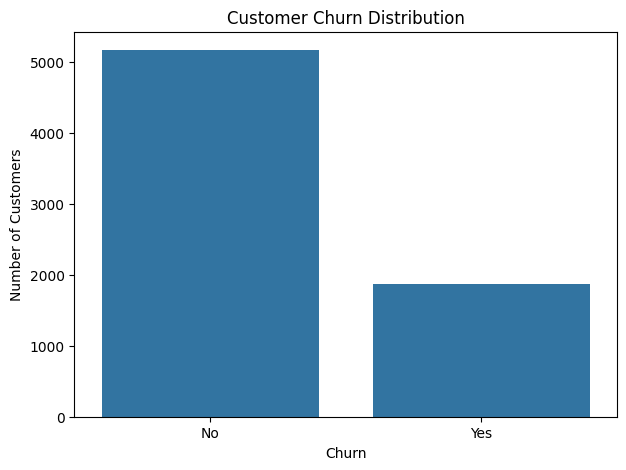

In [10]:
#Churn distribution chart
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [11]:
#Missing values
print("Missing values in each column:")

print(df.isnull().sum())


Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [12]:
#Blank values
blank_counts = df.select_dtypes(include="object").apply(
    lambda column: column.str.strip().eq("").sum()
)

print("Blank values in text columns:")
print(blank_counts)

Blank values in text columns:
customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64


In [13]:
#Check duplicate records
print("Total duplicate rows:", df.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Total duplicate rows: 0
Duplicate customer IDs: 0


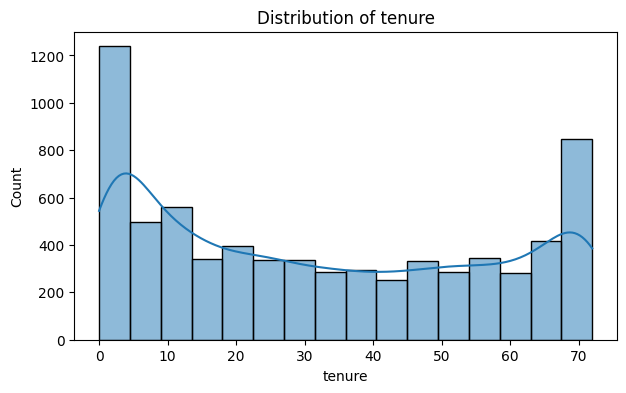

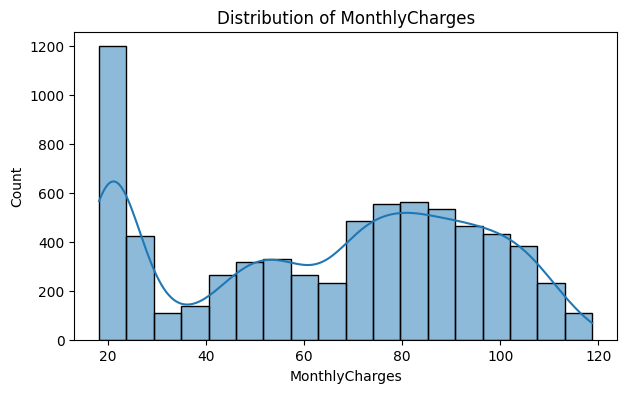

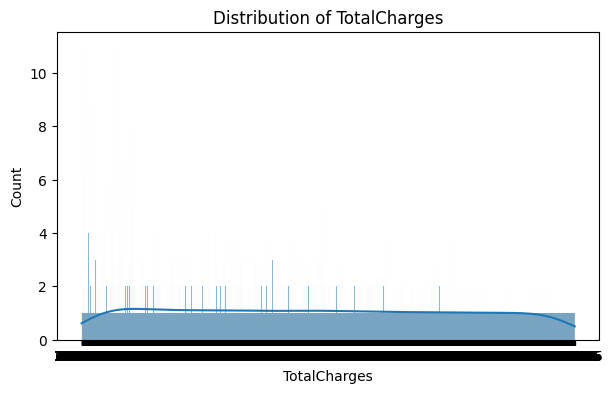

In [14]:
#Numerical distributions
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.show()

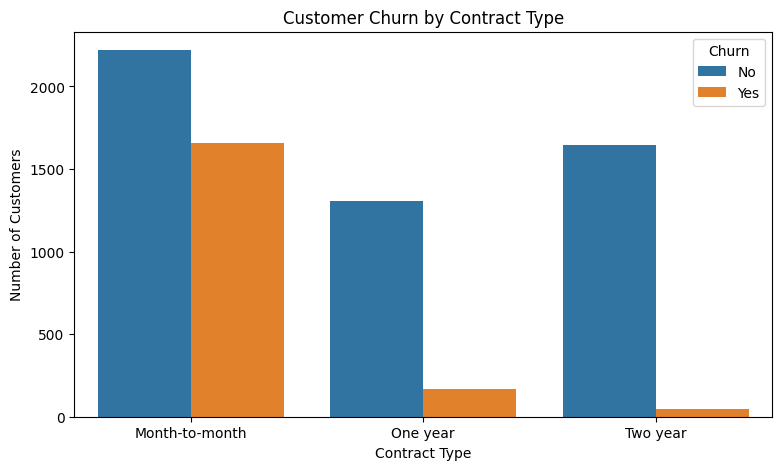

In [15]:
#Explore customer churn by contract type
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

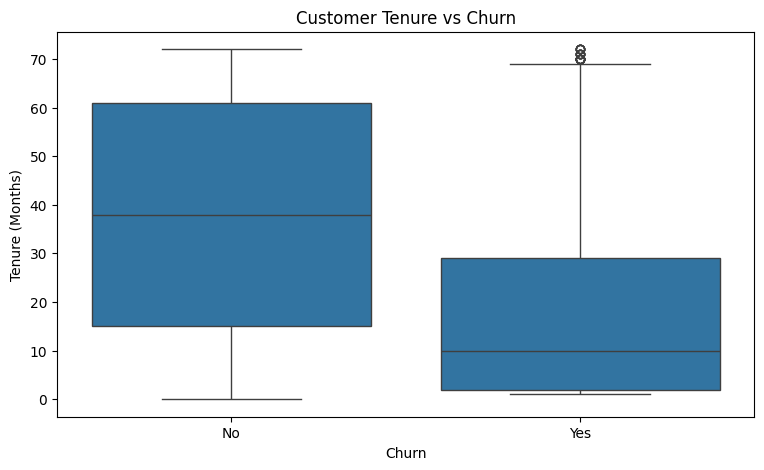

In [16]:
#Explore churn by customer tenure
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

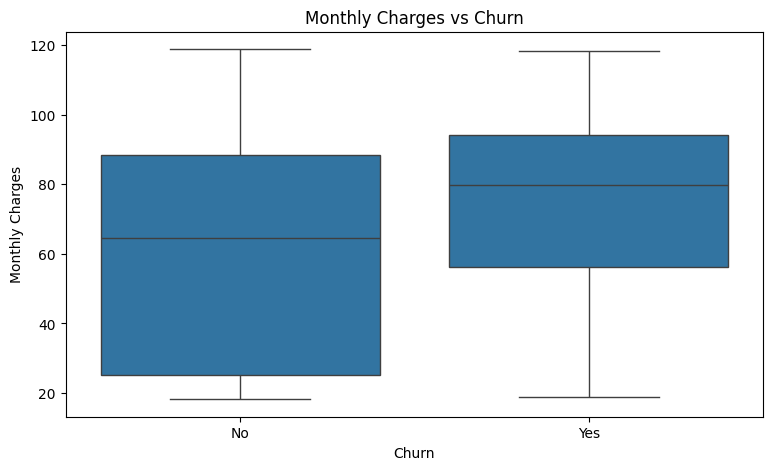

In [17]:
#Explore monthly charges and churn
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [18]:
#Data Cleaning and Preprocessing
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (7043, 21)
Working dataset: (7043, 21)


In [19]:
#Find blank values
blank_total_charges = (
    df_clean["TotalCharges"].astype(str).str.strip() == ""
)

print("Blank TotalCharges records:", blank_total_charges.sum())

display(
    df_clean.loc[
        blank_total_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

Blank TotalCharges records: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [20]:
#Clean and convert
df_clean["TotalCharges"] = (
    df_clean["TotalCharges"]
    .replace(r"^\s*$", np.nan, regex=True)
)

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print(df_clean["TotalCharges"].dtype)
print(
    "Missing TotalCharges:",
    df_clean["TotalCharges"].isnull().sum()
)

float64
Missing TotalCharges: 11


In [21]:
#Investigate missing values
missing_values = df_clean.isnull().sum()

print(
    missing_values[missing_values > 0]
)

#examine the affected records
display(
    df_clean[df_clean["TotalCharges"].isnull()][
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

TotalCharges    11
dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [22]:
#Verify tenure
print(
    df_clean.loc[
        df_clean["TotalCharges"].isnull(),
        "tenure"
    ].value_counts()
)

tenure
0    11
Name: count, dtype: int64


In [23]:
#Remove affected records
before_cleaning = df_clean.shape[0]

df_clean = df_clean.dropna(
    subset=["TotalCharges"]
).copy()

after_cleaning = df_clean.shape[0]

print("Records before:", before_cleaning)
print("Records after:", after_cleaning)
print("Records removed:", before_cleaning - after_cleaning)

Records before: 7043
Records after: 7032
Records removed: 11


In [24]:
#Check duplicate records
print("Duplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df_clean["customerID"].duplicated().sum()
)


Duplicate rows: 0
Duplicate customer IDs: 0


In [25]:
#Check data types again
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

In [26]:
#Final data quality check
print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

Final dataset shape: (7032, 21)

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate records:
0

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             

In [27]:
#Verify numerical columns
print(df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].dtypes)

df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].describe()

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


In [28]:
#Identify categorical columns
categorical_columns = df_clean.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical columns:")

for column in categorical_columns:
    print(column)

Categorical columns:
customerID
gender
Partner
Dependents
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
Churn


In [29]:
#Understand unique categories
for column in categorical_columns:

    print("\nColumn:", column)

    print(df_clean[column].unique())


Column: customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

Column: gender
['Female' 'Male']

Column: Partner
['Yes' 'No']

Column: Dependents
['No' 'Yes']

Column: PhoneService
['No' 'Yes']

Column: MultipleLines
['No phone service' 'No' 'Yes']

Column: InternetService
['DSL' 'Fiber optic' 'No']

Column: OnlineSecurity
['No' 'Yes' 'No internet service']

Column: OnlineBackup
['Yes' 'No' 'No internet service']

Column: DeviceProtection
['No' 'Yes' 'No internet service']

Column: TechSupport
['No' 'Yes' 'No internet service']

Column: StreamingTV
['No' 'Yes' 'No internet service']

Column: StreamingMovies
['No' 'Yes' 'No internet service']

Column: Contract
['Month-to-month' 'One year' 'Two year']

Column: PaperlessBilling
['Yes' 'No']

Column: PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

Column: Churn
['No' 'Yes']


In [30]:
#Encode the target variable
#Our target column is Churn
df_clean["Churn"] = df_clean["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(df_clean["Churn"].value_counts())


print(df_clean["Churn"].dtype)
print(df_clean["Churn"].unique())

Churn
0    5163
1    1869
Name: count, dtype: int64
int64
[0 1]


In [31]:
#Prepare features and target
X = df_clean.drop(
    columns=["Churn", "customerID"]
)

y = df_clean["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


In [32]:
#Identify numerical and categorical features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [33]:
#Split the dataset before encoding
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (5625, 19)
Testing features: (1407, 19)

Training target distribution:
Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64


In [34]:
#Import preprocessing libraries
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

In [35]:
#Create numerical preprocessing
numerical_transformer = StandardScaler()

In [36]:
#Create categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    drop="first"
)

In [37]:
#Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [38]:
#Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (5625, 30)
Testing data shape: (1407, 30)


In [39]:
#Examine transformed features
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nFeature names:")

for feature in feature_names:
    print(feature)

Total transformed features: 30

Feature names:
num__SeniorCitizen
num__tenure
num__MonthlyCharges
num__TotalCharges
cat__gender_Male
cat__Partner_Yes
cat__Dependents_Yes
cat__PhoneService_Yes
cat__MultipleLines_No phone service
cat__MultipleLines_Yes
cat__InternetService_Fiber optic
cat__InternetService_No
cat__OnlineSecurity_No internet service
cat__OnlineSecurity_Yes
cat__OnlineBackup_No internet service
cat__OnlineBackup_Yes
cat__DeviceProtection_No internet service
cat__DeviceProtection_Yes
cat__TechSupport_No internet service
cat__TechSupport_Yes
cat__StreamingTV_No internet service
cat__StreamingTV_Yes
cat__StreamingMovies_No internet service
cat__StreamingMovies_Yes
cat__Contract_One year
cat__Contract_Two year
cat__PaperlessBilling_Yes
cat__PaymentMethod_Credit card (automatic)
cat__PaymentMethod_Electronic check
cat__PaymentMethod_Mailed check


In [40]:
#Verify the transformed data
print("Training data:")
print("Shape:", X_train_processed.shape)
print("Contains missing values:", np.isnan(X_train_processed).any())

print("\nTesting data:")
print("Shape:", X_test_processed.shape)
print("Contains missing values:", np.isnan(X_test_processed).any())

Training data:
Shape: (5625, 30)
Contains missing values: False

Testing data:
Shape: (1407, 30)
Contains missing values: False


In [41]:
#Import Logistic Regression
#Import model
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully")

Logistic Regression imported successfully


In [42]:
#Build the complete ML pipeline
#Create model pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Machine learning pipeline created successfully")

Machine learning pipeline created successfully


In [43]:
#Model training
logistic_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [44]:
#Generate predictions
#Predict churn
y_pred = logistic_model.predict(X_test)

print("First 20 predictions:")
print(y_pred[:20])

First 20 predictions:
[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]


In [45]:
#Calculate prediction probabilities
y_probability = logistic_model.predict_proba(X_test)

print("First 10 probability predictions:")
print(y_probability[:10])

First 10 probability predictions:
[[0.98197782 0.01802218]
 [0.40816793 0.59183207]
 [0.99510847 0.00489153]
 [0.79857566 0.20142434]
 [0.89623768 0.10376232]
 [0.52947906 0.47052094]
 [0.97361037 0.02638963]
 [0.83489636 0.16510364]
 [0.32357051 0.67642949]
 [0.98428263 0.01571737]]


In [46]:
#Evaluate model accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 80.53 %


In [47]:
#Generate the confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[918 115]
 [159 215]]


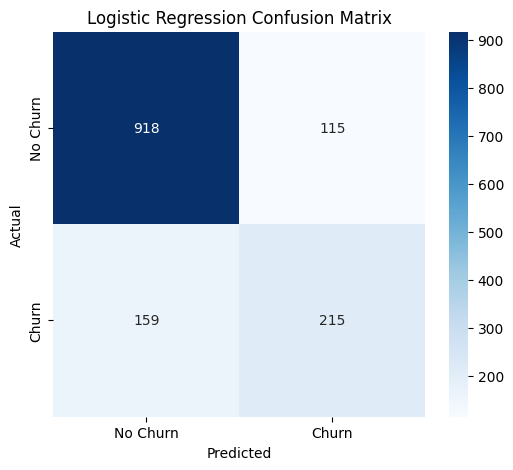

In [48]:
#Visualize
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [49]:
#Classification report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.81      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.81      0.80      1407



In [50]:
#Calculate ROC-AUC
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_test,
    y_probability[:, 1]
)

print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.8361


In [51]:
#Decision Tree vs Random Forest vs Logistic Regression
#Import models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [52]:
#Create Decision Tree pipeline
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

In [53]:
#Train Decision Tree
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [54]:
#Generate predictions
dt_pred = decision_tree_model.predict(X_test)

dt_probability = decision_tree_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(dt_pred[:10])

First 10 predictions:
[0 1 0 0 0 1 0 0 1 0]


In [55]:
#Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [56]:
#Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [57]:
#Generate predictions
rf_pred = random_forest_model.predict(X_test)

rf_probability = random_forest_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(rf_pred[:10])

First 10 predictions:
[0 1 0 0 0 0 0 0 1 0]


In [58]:
#Create evaluation function
def evaluate_model(model_name, y_true, predictions, probabilities):

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

In [59]:
#Compare results
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred,
        y_probability[:, 1]
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_pred,
        dt_probability
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred,
        rf_probability
    )
)

comparison_df = pd.DataFrame(results)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8053,0.6515,0.5749,0.6108,0.8361
1,Decision Tree,0.7164,0.4661,0.4599,0.4630,0.6343
2,Random Forest,0.7868,0.6225,0.5027,0.5562,0.8172


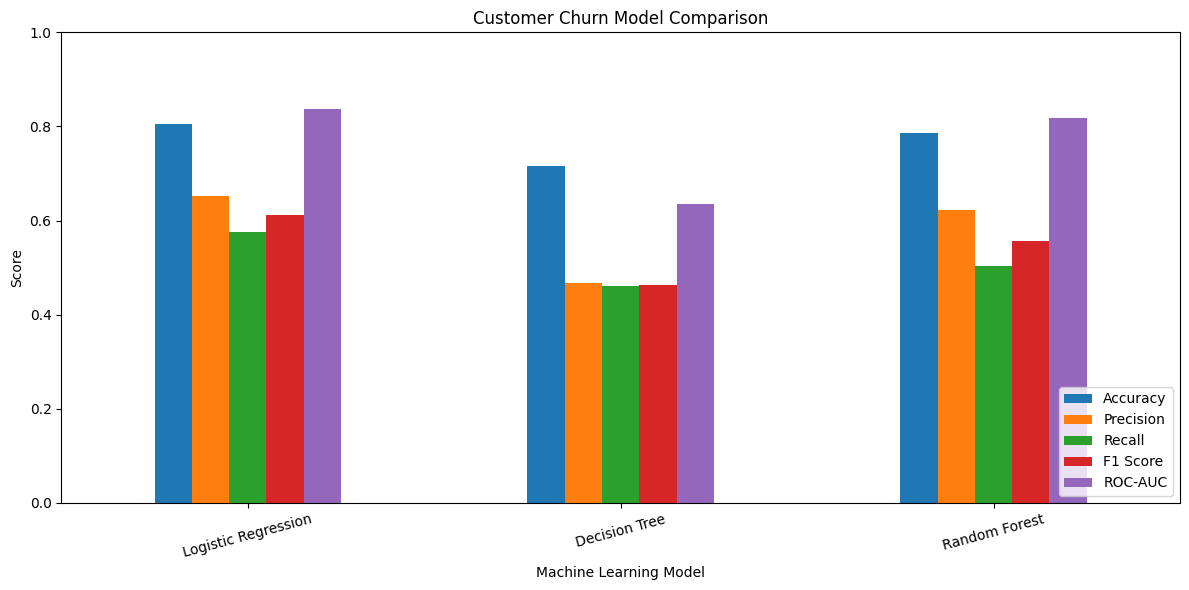

In [60]:
#Visualize model comparison
comparison_plot = comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Customer Churn Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Highest recall model: Logistic Regression


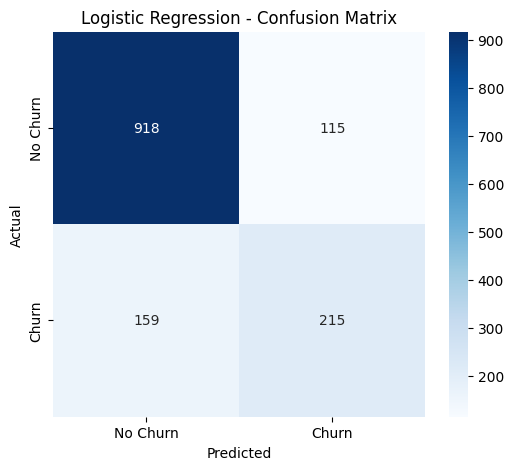

In [61]:
#Examine the best model's confusion matrix
best_model_name = comparison_df.loc[
    comparison_df["Recall"].idxmax(),
    "Model"
]

print("Highest recall model:", best_model_name)

#examine its confusion matrix
model_predictions = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

best_predictions = model_predictions[best_model_name]

best_cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{best_model_name} - Confusion Matrix")

plt.show()

In [63]:
#Import optimization tools
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)



In [64]:
#Create the cross-validation strategy
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [65]:
#Optimize Logistic Regression
#Parameter grid
logistic_parameters = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

In [66]:
#Grid Search
logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_parameters,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

logistic_grid.fit(X_train, y_train)

print("Best parameters:")
print(logistic_grid.best_params_)

print("\nBest cross-validation recall:")
print(logistic_grid.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}

Best cross-validation recall:
0.8020066889632107


In [67]:
#Optimize Decision Tree
#Parameter grid
decision_tree_parameters = {
    "classifier__max_depth": [3, 5, 8, 10, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

In [68]:
#Grid Search
decision_tree_grid = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=decision_tree_parameters,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

decision_tree_grid.fit(X_train, y_train)

print("Best parameters:")
print(decision_tree_grid.best_params_)

print("\nBest cross-validation recall:")
print(decision_tree_grid.best_score_)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best cross-validation recall:
0.8889632107023411


In [69]:
#Optimize Random Forest
#Parameter grid
random_forest_parameters = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__class_weight": [None, "balanced"]
}

In [70]:
#Grid Search
random_forest_grid = GridSearchCV(
    estimator=random_forest_model,
    param_grid=random_forest_parameters,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_forest_grid.fit(X_train, y_train)

print("Best parameters:")
print(random_forest_grid.best_params_)

print("\nBest cross-validation recall:")
print(random_forest_grid.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best cross-validation recall:
0.8040133779264215


In [71]:
#Compare optimized models
optimized_models = {
    "Optimized Logistic Regression": logistic_grid.best_estimator_,
    "Optimized Decision Tree": decision_tree_grid.best_estimator_,
    "Optimized Random Forest": random_forest_grid.best_estimator_
}

optimized_results = []

for model_name, model in optimized_models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    optimized_results.append(
        evaluate_model(
            model_name,
            y_test,
            predictions,
            probabilities
        )
    )

optimized_comparison = pd.DataFrame(optimized_results)

display(
    optimized_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Optimized Logistic Regression,0.7264,0.4909,0.7941,0.6067,0.8353
1,Optimized Decision Tree,0.6361,0.4127,0.8717,0.5601,0.7823
2,Optimized Random Forest,0.7242,0.4886,0.8048,0.6081,0.8356


In [72]:
#Compare baseline and optimized models
baseline_results = comparison_df.copy()

final_comparison = pd.concat(
    [baseline_results, optimized_comparison],
    ignore_index=True
)

display(
    final_comparison.sort_values(
        by="Recall",
        ascending=False
    ).style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
4,Optimized Decision Tree,0.6361,0.4127,0.8717,0.5601,0.7823
5,Optimized Random Forest,0.7242,0.4886,0.8048,0.6081,0.8356
3,Optimized Logistic Regression,0.7264,0.4909,0.7941,0.6067,0.8353
0,Logistic Regression,0.8053,0.6515,0.5749,0.6108,0.8361
2,Random Forest,0.7868,0.6225,0.5027,0.5562,0.8172
1,Decision Tree,0.7164,0.4661,0.4599,0.4630,0.6343


In [73]:
#Create validation split
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model fitting data:", X_fit.shape)
print("Validation data:", X_val.shape)

Model fitting data: (4500, 19)
Validation data: (1125, 19)


In [74]:
#Tune Logistic Regression using fitting data
threshold_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_parameters,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

threshold_search.fit(X_fit, y_fit)

print("Best parameters:")
print(threshold_search.best_params_)

print("Best CV recall:")
print(threshold_search.best_score_)

Best parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Best CV recall:
0.8043340306834029


In [76]:
#Generate validation probabilities
validation_probabilities = (
    threshold_search.best_estimator_
    .predict_proba(X_val)[:, 1]
)

print("First 10 churn probabilities:")
print(validation_probabilities[:10])

First 10 churn probabilities:
[0.79901535 0.37521872 0.39428721 0.16307175 0.14492343 0.62162541
 0.03515852 0.40518072 0.17385549 0.25875463]


In [77]:
#Experiment with different thresholds
thresholds = [
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65, 0.70
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(y_val, predictions),
        "F1 Score": f1_score(y_val, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.30,0.6516,0.4279,0.9231,0.5847
1,0.35,0.6764,0.4459,0.8963,0.5956
2,0.40,0.7067,0.4719,0.8696,0.6118
3,0.45,0.7342,0.5000,0.8261,0.6230
4,0.50,0.7529,0.5235,0.7826,0.6273
5,0.55,0.7716,0.5515,0.7525,0.6365
6,0.60,0.7716,0.5559,0.6990,0.6193
7,0.65,0.7804,0.5798,0.6321,0.6048
8,0.70,0.7822,0.5944,0.5686,0.5812


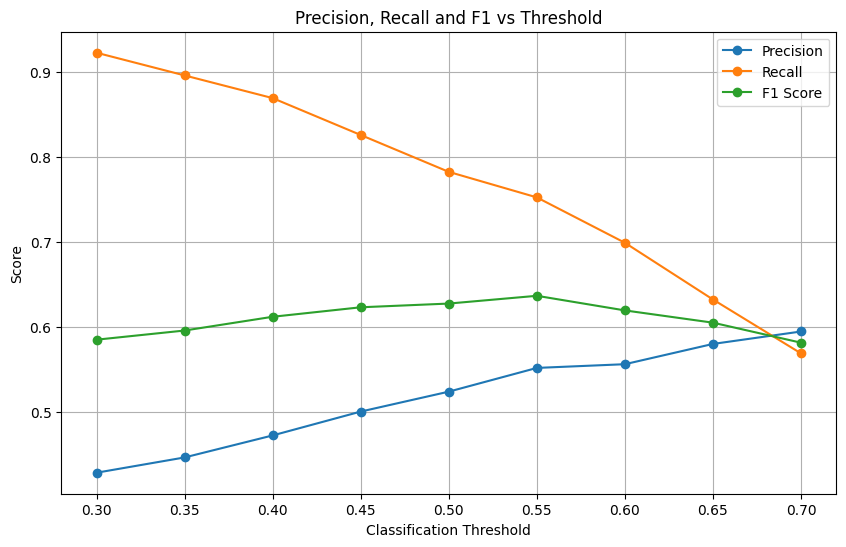

In [78]:
#Visualize the threshold trade-off
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold")

plt.legend()
plt.grid(True)
plt.show()

In [79]:
#threshold based on business requirements(F1-Score)
best_threshold_row = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Selected threshold:", best_threshold)
print("Validation precision:", best_threshold_row["Precision"])
print("Validation recall:", best_threshold_row["Recall"])
print("Validation F1:", best_threshold_row["F1 Score"])

Selected threshold: 0.55
Validation precision: 0.5514705882352942
Validation recall: 0.7525083612040134
Validation F1: 0.6364922206506365


In [80]:
#Prepare the final model
from sklearn.base import clone

final_churn_model = clone(
    threshold_search.best_estimator_
)

final_churn_model.fit(X_train, y_train)

print("Final model trained on complete training data.")

Final model trained on complete training data.


In [81]:
#Evaluate once on the test set
final_test_probabilities = (
    final_churn_model.predict_proba(X_test)[:, 1]
)

final_test_predictions = (
    final_test_probabilities >= best_threshold
).astype(int)

print("Final test accuracy:",
      accuracy_score(y_test, final_test_predictions))

print("\nClassification report:")

print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=["No Churn", "Churn"]
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, final_test_predictions))

Final test accuracy: 0.746268656716418

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81      1033
       Churn       0.52      0.76      0.61       374

    accuracy                           0.75      1407
   macro avg       0.71      0.75      0.71      1407
weighted avg       0.79      0.75      0.76      1407


Confusion matrix:
[[765 268]
 [ 89 285]]


In [82]:
#Feature Importance
#Random Forest model
best_rf_model = random_forest_grid.best_estimator_

print("Optimized Random Forest loaded.")

Optimized Random Forest loaded.


In [83]:
#Extract feature names after preprocessing
preprocessor_fitted = best_rf_model.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print(feature_names)

Total transformed features: 30
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Male' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No internet service' 'cat__TechSupport_Yes'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No internet service' 'cat__StreamingMovies_Yes'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__PaperlessBilling_Yes' 'cat__PaymentMethod_Credit card (automatic)'
 'cat__PaymentMethod_Electronic check' 'cat__PaymentMethod_Mailed check']


In [84]:
#Calculate Random Forest feature importance
rf_classifier = best_rf_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
1,num__tenure,0.181948
25,cat__Contract_Two year,0.159417
3,num__TotalCharges,0.106992
10,cat__InternetService_Fiber optic,0.090618
28,cat__PaymentMethod_Electronic check,0.069265
2,num__MonthlyCharges,0.052872
24,cat__Contract_One year,0.047303
13,cat__OnlineSecurity_Yes,0.041417
22,cat__StreamingMovies_No internet service,0.033762
16,cat__DeviceProtection_No internet service,0.031444


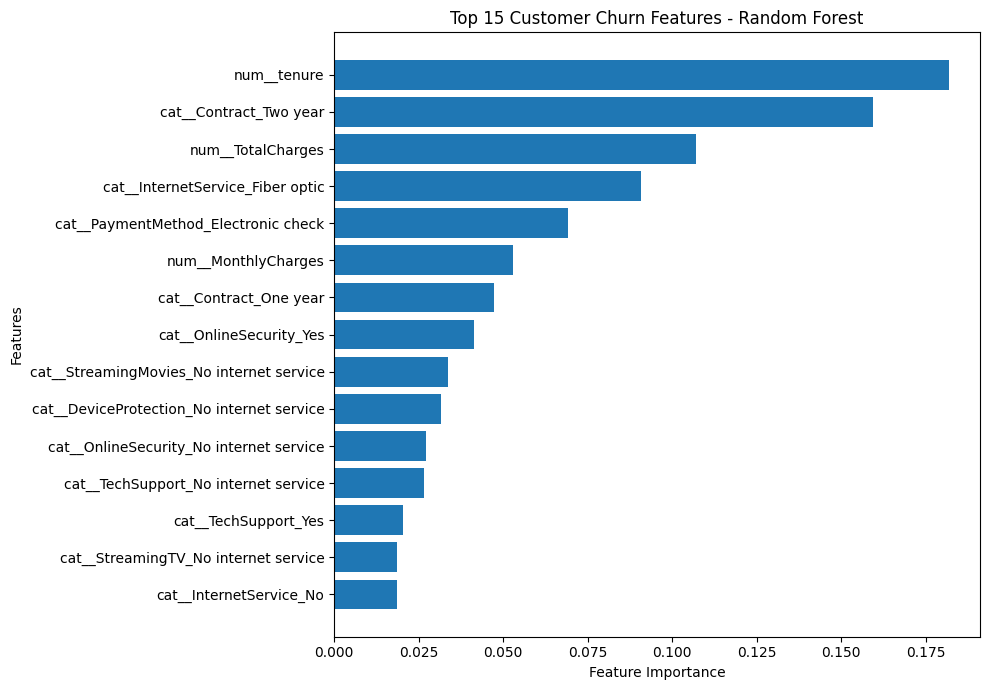

In [85]:
#Visualize the top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Customer Churn Features - Random Forest")

plt.tight_layout()
plt.show()

In [86]:
#Calculate permutation importance
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    best_rf_model,
    X_val,
    y_val,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

display(permutation_df.head(15))

,Feature,Importance,Std
7,InternetService,0.029851,0.010624
14,Contract,0.029673,0.012042
4,tenure,0.025493,0.007377
16,PaymentMethod,0.013663,0.004208
9,OnlineBackup,0.007164,0.002858
18,TotalCharges,0.007137,0.005379
17,MonthlyCharges,0.006151,0.006978
3,Dependents,0.005381,0.002955
12,StreamingTV,0.005252,0.002121
15,PaperlessBilling,0.005200,0.003485


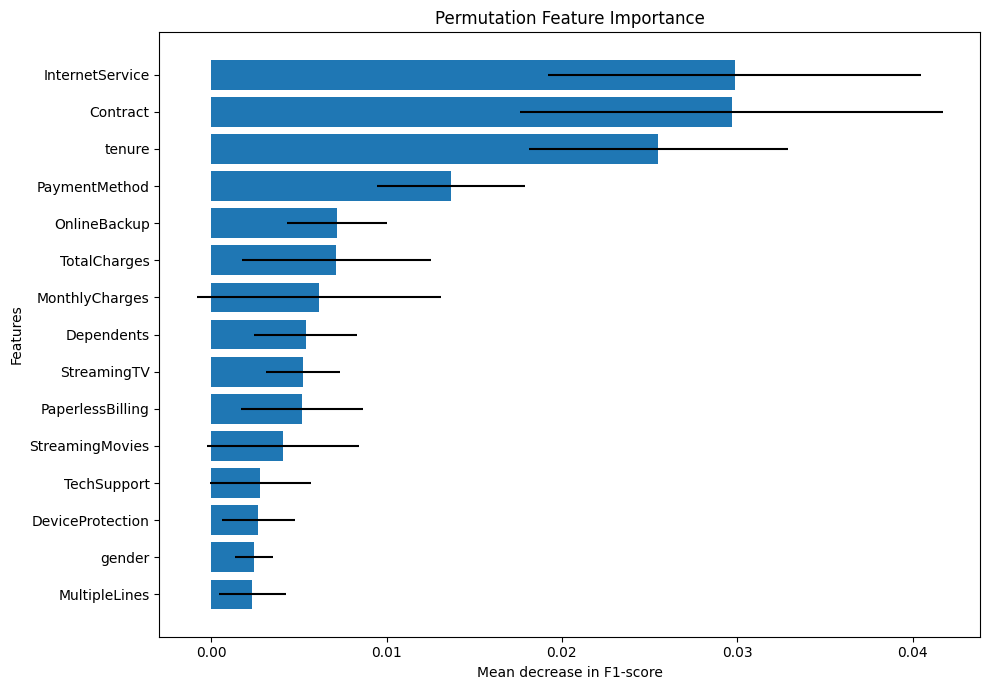

In [87]:
#Visualize permutation importance
top_permutation = permutation_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation["Feature"],
    top_permutation["Importance"],
    xerr=top_permutation["Std"]
)

plt.xlabel("Mean decrease in F1-score")
plt.ylabel("Features")
plt.title("Permutation Feature Importance")

plt.tight_layout()
plt.show()

In [88]:
#Explainable AI using SHAP
#Install and import SHAP
!pip install shap
import shap
import numpy as np

In [89]:
#Prepare the transformed data
X_val_transformed = (
    best_rf_model.named_steps["preprocessor"]
    .transform(X_val)
)

print("Transformed validation shape:",
      X_val_transformed.shape)

Transformed validation shape: (1125, 30)


In [90]:
#Prepare the transformed data
#use the fitted Random Forest preprocessing pipeline
X_val_transformed = (
    best_rf_model.named_steps["preprocessor"]
    .transform(X_val)
)

print("Transformed validation shape:",
      X_val_transformed.shape)


Transformed validation shape: (1125, 30)


In [91]:
#Create a SHAP explainer
explainer = shap.TreeExplainer(
    best_rf_model.named_steps["classifier"]
)

shap_values = explainer(
    X_val_transformed
)

print("SHAP values calculated.")

SHAP values calculated.


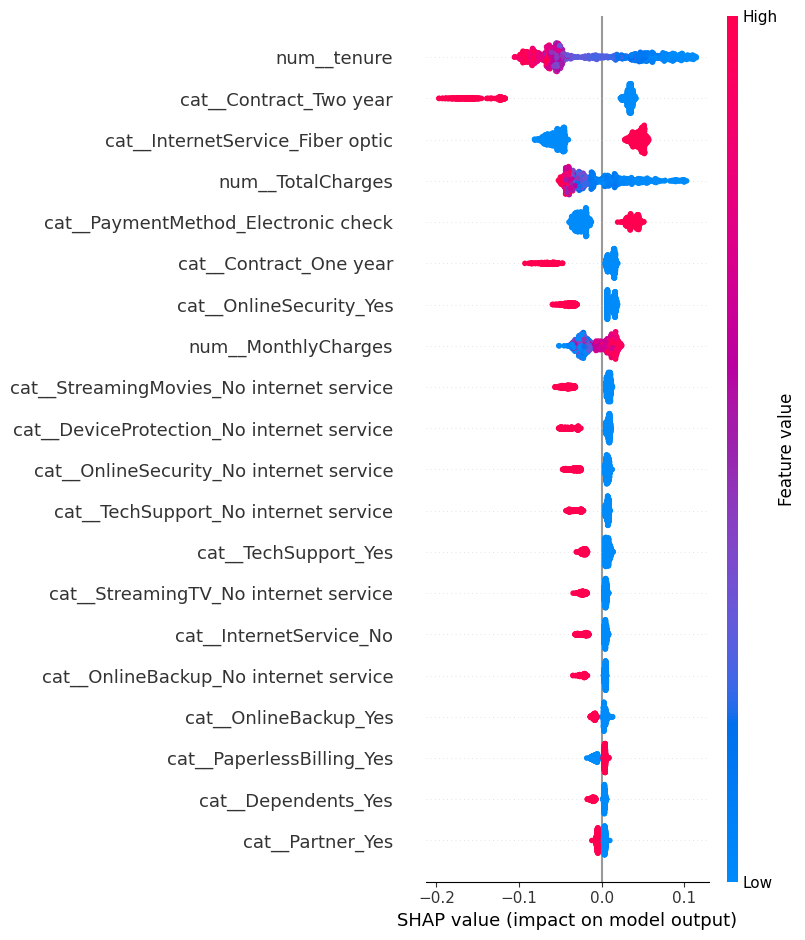

In [92]:
#Understand overall feature impact
shap.summary_plot(
    shap_values[:, :, 1],
    X_val_transformed,
    feature_names=feature_names,
    show=True
)

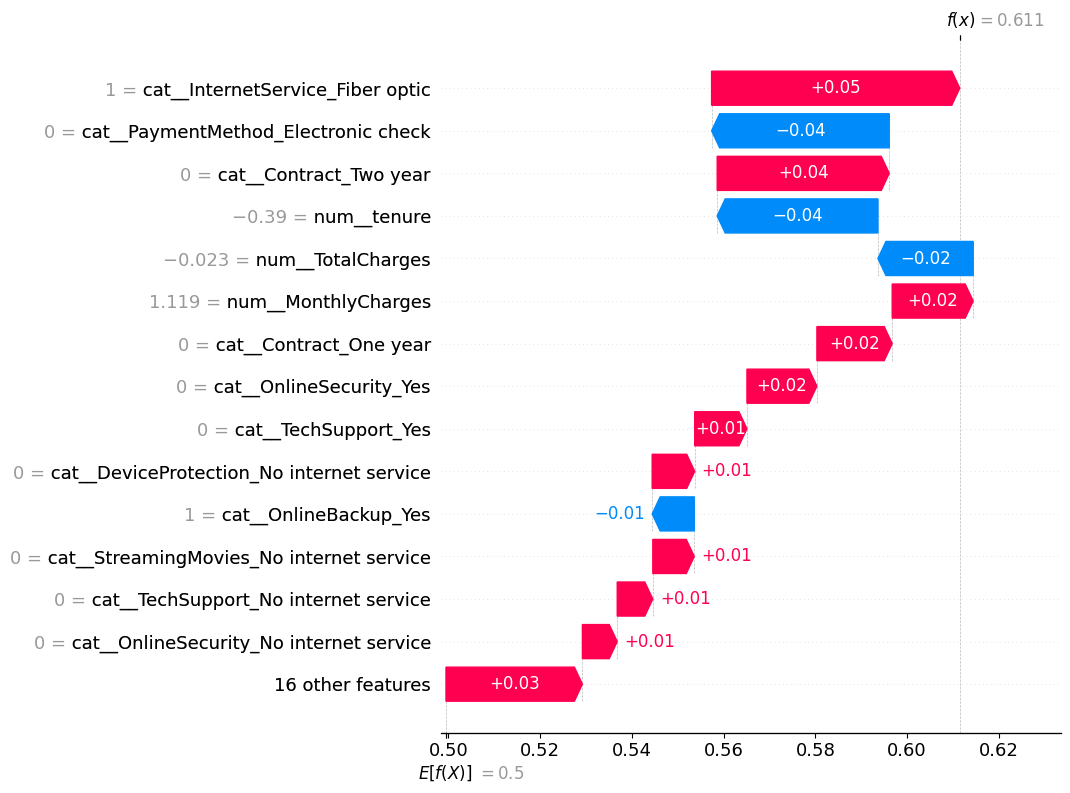

In [94]:
# Convert transformed validation data into a dense array
if hasattr(X_val_transformed, "toarray"):
    X_val_dense = X_val_transformed.toarray()
else:
    X_val_dense = np.asarray(X_val_transformed)

# Create SHAP Explanation for churn class (class 1)
churn_explanation = shap.Explanation(
    values=shap_values.values[:, :, 1],
    base_values=shap_values.base_values[:, 1],
    data=X_val_dense,
    feature_names=list(feature_names)
)

# Explain the first customer
customer_index = 0

shap.plots.waterfall(
    churn_explanation[customer_index],
    max_display=15
)

In [99]:
#Final Model Selection and Reliable Evaluation
#Prepare the cleaned dataset
# Create features and target from df_clean to avoid string-to-float errors

X_final = df_clean.drop(
    columns=["Churn", "customerID"]
)

y_final = df_clean["Churn"]

print("Features shape:", X_final.shape)
print("Target shape:", y_final.shape)

print("\nTarget distribution:")
print(y_final.value_counts(normalize=True))

Features shape: (7032, 19)
Target shape: (7032,)

Target distribution:
Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


In [100]:
#Create the training, validation and test sets
from sklearn.model_selection import train_test_split

# First split: 60% training, 40% remaining
X_train_final, X_remaining, y_train_final, y_remaining = (
    train_test_split(
        X_final,
        y_final,
        test_size=0.40,
        random_state=42,
        stratify=y_final
    )
)

# Second split: divide remaining 40% equally
X_val_final, X_test_final, y_val_final, y_test_final = (
    train_test_split(
        X_remaining,
        y_remaining,
        test_size=0.50,
        random_state=42,
        stratify=y_remaining
    )
)

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Training: (4219, 19)
Validation: (1406, 19)
Testing: (1407, 19)


In [101]:
#Build a leakage-safe preprocessing and training pipeline
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

final_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print(final_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                        

In [102]:
#Optimize Logistic Regression
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__solver": ["lbfgs", "liblinear"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

final_grid = GridSearchCV(
    estimator=final_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

final_grid.fit(X_train_final, y_train_final)

print("Best parameters:")
print(final_grid.best_params_)

print("\nBest cross-validation recall:")
print(final_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'classifier__C': 10, 'classifier__solver': 'liblinear'}

Best cross-validation recall:
0.7984285714285714


In [103]:
#Select the classification threshold
from sklearn.metrics import precision_score, recall_score, f1_score

best_final_model = final_grid.best_estimator_

validation_probabilities = best_final_model.predict_proba(
    X_val_final
)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):

    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val_final,
            validation_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_final,
            validation_predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_val_final,
            validation_predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Precision,Recall,F1 Score
0,0.30,0.416567,0.927807,0.574979
1,0.35,0.432950,0.906417,0.585998
2,0.40,0.446304,0.855615,0.586618
3,0.45,0.474085,0.831551,0.603883
4,0.50,0.500000,0.799465,0.615226
5,0.55,0.530275,0.772727,0.628945
6,0.60,0.549495,0.727273,0.626007
7,0.65,0.579196,0.655080,0.614806
8,0.70,0.584699,0.572193,0.578378


In [104]:
#Select the best threshold
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Selected threshold:", best_threshold)

Selected threshold: 0.55


In [105]:
#Perform final test evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

test_probabilities = best_final_model.predict_proba(
    X_test_final
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)

print("\nTest Accuracy:",
      accuracy_score(y_test_final, test_predictions))

print("\nTest ROC-AUC:",
      roc_auc_score(y_test_final, test_probabilities))

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    test_predictions,
    target_names=["No Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, test_predictions))

Selected threshold: 0.55

Test Accuracy: 0.7540867093105899

Test ROC-AUC: 0.8487156457232192

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.82      1033
       Churn       0.52      0.79      0.63       374

    accuracy                           0.75      1407
   macro avg       0.72      0.77      0.72      1407
weighted avg       0.81      0.75      0.77      1407


Confusion Matrix:
[[765 268]
 [ 78 296]]


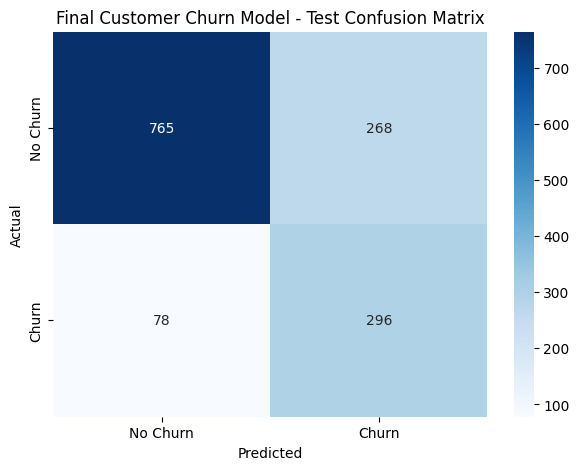

In [106]:
#Visualize the final confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test_final,
    test_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Customer Churn Model - Test Confusion Matrix")

plt.show()

In [107]:
#Save the final model
import joblib
import os

os.makedirs("models", exist_ok=True)

model_artifact = {
    "pipeline": best_final_model,
    "threshold": float(best_threshold),
    "feature_columns": list(X_train_final.columns),
    "model_name": "Logistic Regression",
    "target_mapping": {
        "No": 0,
        "Yes": 1
    }
}

joblib.dump(
    model_artifact,
    "models/customer_churn_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


In [108]:
#Verify the saved model
loaded_artifact = joblib.load(
    "models/customer_churn_model.pkl"
)

print("Model:", loaded_artifact["model_name"])
print("Threshold:", loaded_artifact["threshold"])
print("Number of input features:",
      len(loaded_artifact["feature_columns"]))

Model: Logistic Regression
Threshold: 0.55
Number of input features: 19


In [109]:
#Upload the trained model
import os

model_path = "models/customer_churn_model.pkl"

if os.path.exists(model_path):
    print("Model file found!")
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model file not found. We need to save it first.")

Model file found!
File size: 7.97 KB


In [110]:
from google.colab import files

files.download("models/customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [115]:
!git clone https://github.com/jatinkumar-creator/machine-learning-portfolio

Cloning into 'machine-learning-portfolio'...
remote: Enumerating objects: 301, done.
remote: Counting objects: 100% (301/301), done.
remote: Compressing objects: 100% (287/287), done.
remote: Total 301 (delta 193), reused 15 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (301/301), 1.49 MiB | 8.20 MiB/s, done.
Resolving deltas: 100% (193/193), done.


In [118]:
%cd /content/machine-learning-portfolio/projects/01_customer_churn

/content/machine-learning-portfolio/projects/01_customer_churn


In [119]:
import os

print("Current directory:", os.getcwd())

print("app.py exists:", os.path.exists("app.py"))

print("requirements.txt exists:",
      os.path.exists("requirements.txt"))

print("Model exists:",
      os.path.exists("models/customer_churn_model.pkl"))

Current directory: /content/machine-learning-portfolio/projects/01_customer_churn
app.py exists: True
requirements.txt exists: True
Model exists: True


In [120]:
!pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 38.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 65.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [121]:
#Verify the model and application
import os

print("app.py exists:", os.path.exists("app.py"))
print(
    "Model exists:",
    os.path.exists("models/customer_churn_model.pkl")
)

app.py exists: True
Model exists: True


In [139]:
%cd /content/machine-learning-portfolio

/content/machine-learning-portfolio


In [ ]:
!git pull origin main

In [141]:
%cd /content/machine-learning-portfolio/projects/01_customer_churn

/content/machine-learning-portfolio/projects/01_customer_churn


In [ ]:
!pip install -r requirements.txt

In [143]:
from pathlib import Path

print("App exists:", Path("app.py").exists())
print("Requirements exist:", Path("requirements.txt").exists())
print(
    "Model exists:",
    Path("models/customer_churn_model.pkl").exists()
)

App exists: True
Requirements exist: True
Model exists: True


In [144]:
!python -m py_compile app.py
print("Python syntax check completed.")

Python syntax check completed.


In [145]:
import joblib

artifact = joblib.load("models/customer_churn_model.pkl")

print("Artifact type:", type(artifact))

if isinstance(artifact, dict):
    print("Available keys:", artifact.keys())
    print("Threshold:", artifact["threshold"])
    print("Feature count:", len(artifact["feature_columns"]))
    print("Pipeline:", artifact["pipeline"])

Artifact type: <class 'dict'>
Available keys: dict_keys(['pipeline', 'threshold', 'feature_columns', 'model_name', 'target_mapping'])
Threshold: 0.55
Feature count: 19
Pipeline: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   '

In [152]:
!streamlit run app.py --server.port 8503 --server.address 0.0.0.0 --server.headless true > /content/streamlit_8503.log 2>&1 &

In [153]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8503 --no-autoupdate